# Part V — The verdict: model against reality
**Question:** *could we have predicted the 2026 season, race by race?* Before each 2026 race, every model is re-trained on everything that happened before it (car profile and k-means included), exactly like a live forecast. Then we compare with what really happened.

In [1]:
import sys, warnings; sys.path.insert(0, '..'); warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from f1duel.data import build, TEAM_STATS
from f1duel.plots import style, title, save, BLUE, ORANGE, AQUA, GREY, INK, INK2, MUTED, TIER_COLORS
style(); pd.set_option('display.width', 140); pd.set_option('display.max_columns', 20)
d = build()
import json
S = json.load(open('../results/summary.json')); P = pd.read_csv('../results/predictions.csv')
from f1duel.model import scorers_named, pick10
Q = P[P.test == '2026']
rows = []
for (r, gp), g in Q.groupby(['round', 'gp_name']):
    fav = g.loc[g.p_win.idxmax()]; win = g[g.win == 1]
    rows.append({'Round': r, 'Grand Prix': gp,
                 'Grid rule': int(g.top10[pick10(g, 'grid', True) == 1].sum()),
                 'Model': int(g.top10[pick10(g, 'p_top10_logit') == 1].sum()),
                 'Model favourite': f"{fav.driver_name} ({fav.p_win:.0%})",
                 'Real winner': win.driver_name.iloc[0] if len(win) else '—'})
T = pd.DataFrame(rows).set_index('Round'); T

,Grand Prix,Grid rule,Model,Model favourite,Real winner
Round,,,,,
1,Australia,8,8,George Russell (71%),George Russell
2,China,8,7,Kimi Antonelli (62%),Kimi Antonelli
3,Japan,7,8,Kimi Antonelli (62%),Kimi Antonelli
4,Miami,8,8,Kimi Antonelli (53%),Kimi Antonelli
5,Canada,6,6,George Russell (58%),Kimi Antonelli
6,Monaco,6,6,Kimi Antonelli (74%),Kimi Antonelli
7,Barcelona-Catalunya,7,8,George Russell (68%),Lewis Hamilton
8,Austria,10,10,George Russell (55%),George Russell
9,Great Britain,7,7,Kimi Antonelli (59%),Charles Leclerc


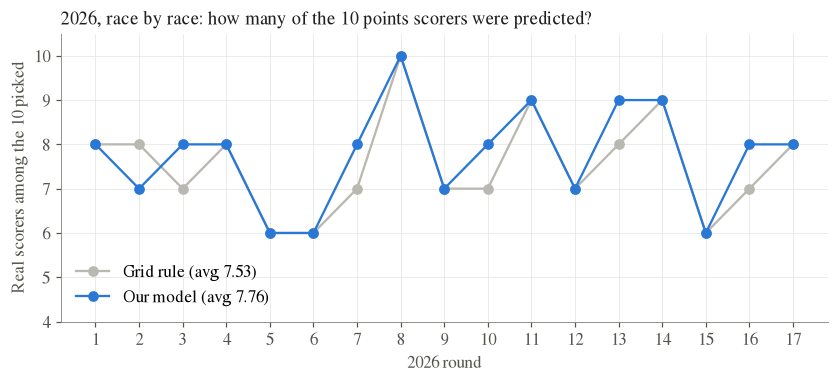

Model better in 5 races, equal in 11, worse in 1.


In [2]:
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.plot(T.index, T['Grid rule'], 'o-', color=GREY, label=f"Grid rule (avg {T['Grid rule'].mean():.2f})")
ax.plot(T.index, T['Model'], 'o-', color=BLUE, label=f"Our model (avg {T['Model'].mean():.2f})")
ax.set_xticks(T.index); ax.set_xlabel('2026 round'); ax.set_ylabel('Real scorers among the 10 picked'); ax.set_ylim(4, 10.5); ax.legend(loc='lower left')
title(ax, '2026, race by race: how many of the 10 points scorers were predicted?'); save(fig, '05_2026'); plt.show()
print(f"Model better in {(T.Model > T['Grid rule']).sum()} races, equal in {(T.Model == T['Grid rule']).sum()}, worse in {(T.Model < T['Grid rule']).sum()}.")

### Monaco and other grid-dependent tracks (the professor's question)
*"Monaco is very grid dependent, and many GPs might be similar."* We group the 2020–2025 test races by track. A track's **grid dependence** is the share of its top-10 finishers who started in the top 10, measured on **2010–2019 only**, so the groups are fixed before looking at the test races.

,races,scorers_grid,scorers_model,duel_grid,duel_model,gain_scorers,gain_duels_pts
All races,131.0,7.710,7.855,0.755,0.775,0.145,1.976
Street circuits,34.0,7.706,7.765,0.754,0.770,0.059,1.599
Most grid-dependent third of tracks,34.0,7.618,7.882,0.747,0.780,0.265,3.335
Monaco,5.0,9.200,8.400,0.853,0.811,-0.800,-4.235


Most grid-dependent tracks (2010-2019): hungaroring, istanbul, mexico-city, montreal, monza, nurburgring, paul-ricard, shanghai, yas-marina
Monaco 2010-2019: 74% of top-10 finishers started top 10 (median track: 76%)


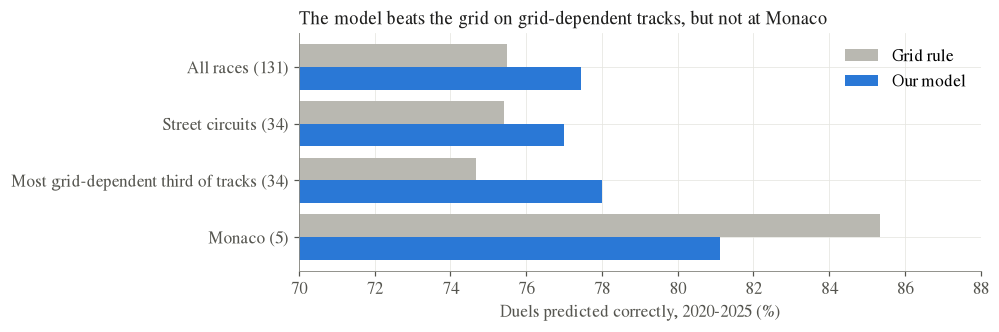

In [3]:
TR = S['tracks']
G = pd.DataFrame({k: v for k, v in TR.items() if isinstance(v, dict)}).T
G['gain_scorers'] = G.scorers_model - G.scorers_grid; G['gain_duels_pts'] = 100 * (G.duel_model - G.duel_grid)
display(G.round(3))
print('Most grid-dependent tracks (2010-2019):', ', '.join(TR['grid_dependent_tracks']))
print(f"Monaco 2010-2019: {TR['monaco_grid_dependence_2010_2019']:.0%} of top-10 finishers started top 10 (median track: {TR['grid_dependence_median_2010_2019']:.0%})")
fig, ax = plt.subplots(figsize=(8, 2.8)); y = np.arange(len(G))[::-1]
ax.barh(y + 0.2, G.duel_grid * 100, 0.4, color=GREY, label='Grid rule'); ax.barh(y - 0.2, G.duel_model * 100, 0.4, color=BLUE, label='Our model')
ax.set_yticks(y); ax.set_yticklabels([f"{n} ({int(r)})" for n, r in zip(G.index, G.races)]); ax.set_xlim(70, 88)
ax.set_xlabel('Duels predicted correctly, 2020-2025 (%)'); ax.legend(loc='upper right')
title(ax, 'The model beats the grid on grid-dependent tracks, but not at Monaco'); save(fig, '05_tracks'); plt.show()

**Reading.** At **Monaco the grid wins** (5 races): it names 9.2 of the 10 scorers against 8.0 for the model. Overtaking is almost impossible there, so any change the model makes to the grid order is a mistake. But Monaco is an exception, not a family: on the **third of tracks that depended most on the grid in 2010–2019** and on **street circuits**, the model still beats the grid. Monaco itself was *not* unusually grid-dependent in 2010–2019; it became so after 2021 (bigger cars), which is why a rule learnt from the past could not anticipate it.

### One model or two? (normal tracks vs hard-to-overtake tracks)
Instead of one logistic regression for every track, we train **two**: one on normal tracks and one on the tracks where overtaking is hardest (Monaco, Zandvoort, Hungaroring, Marina Bay, Madring). Each has its own weights $\theta$. For comparison, a second split defined from the data (top third of circuits by share of top-10 finishers who started in the top 10) gives the same conclusion. Code: `f1duel/tracks.py`.

,Normal track,Hard-to-overtake track
grid,-1.31,-1.01
log_grid,0.47,-0.04
quali_gap,-0.08,0.03
practice_gap,-0.36,-0.52
car_perf,0.74,0.80
car_rel,0.04,-0.03
tier_top,-0.12,-0.26
tier_unrel,-0.04,0.06
intercept,-0.14,-0.11


n  Grid rule  One model  Two models  Two models (data split)  Cross-entropy one  Cross-entropy two
Test      Races                                                                                                                       
2020-2025 All races               131      7.710      7.855       7.878                    7.840              0.488              0.489
          Normal track            111      7.676      7.838       7.847                    7.811              0.492              0.492
          Hard-to-overtake track   20      7.900      7.950       8.050                    8.000              0.467              0.474
2026      All races                17      7.529      7.765       7.765                    7.765              0.480              0.480
          Normal track             12      7.417      7.750       7.750                    7.750              0.488              0.486
          Hard-to-overtake track    5      7.800      7.800       7.800                    7.800              0.462              0.464

Hard-to-overtake tracks: Monaco, Zandvoort (Netherlands), Hungaroring (Hungary), Marina Bay (Singapore), Madring (Madrid, Spain)


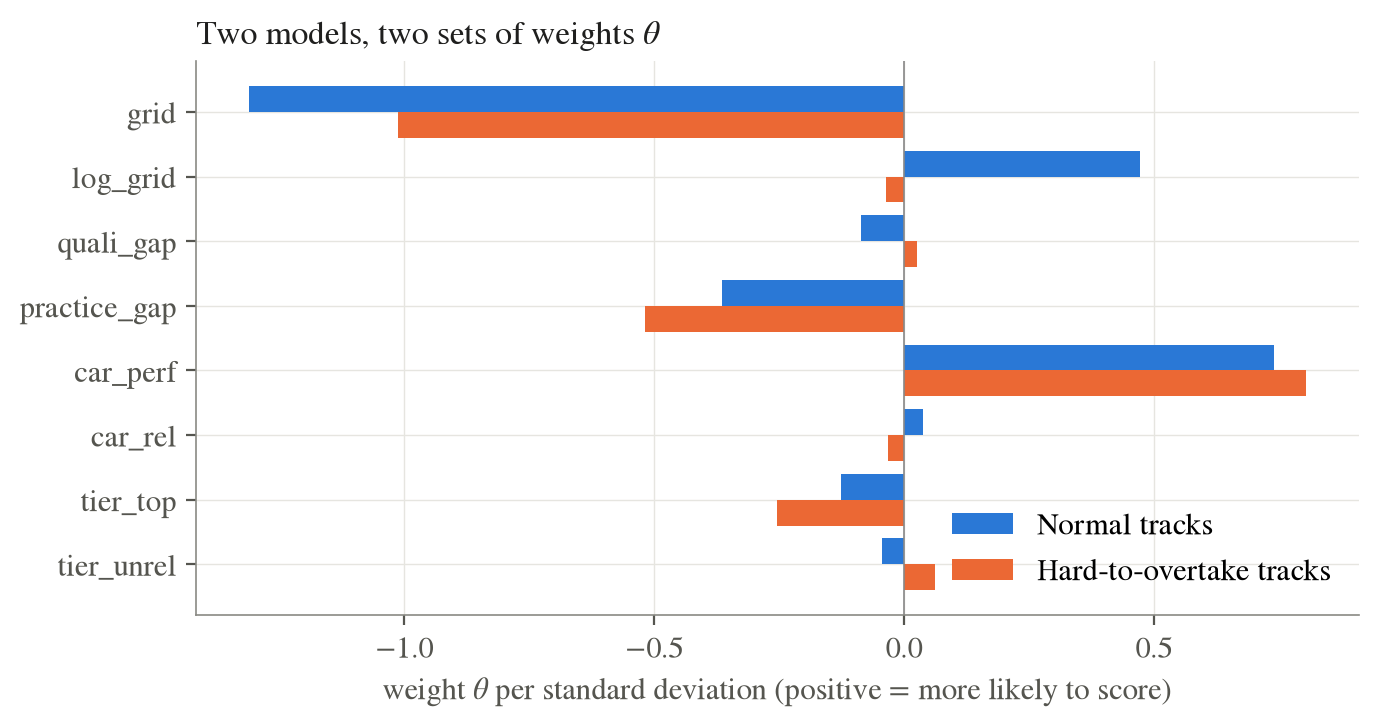

In [4]:
T = json.load(open('../results/tracks_summary.json'))
th = pd.DataFrame(T['final']['thetas']); display(th.round(2))
rows = [{'Test': t, 'Races': g, 'n': v['races'], 'Grid rule': v['named_grid'], 'One model': v['named_one'], 'Two models': v['named_two'],
         'Two models (data split)': v['named_two_data'], 'Cross-entropy one': v['ce_one'], 'Cross-entropy two': v['ce_two']}
        for t in ('2020-2025', '2026') for g, v in T[t].items()]
display(pd.DataFrame(rows).set_index(['Test', 'Races']).round(3))
print('Hard-to-overtake tracks:', ', '.join(x['name'] for x in T['final']['hard_tracks']))
from IPython.display import Image; display(Image('../figures/05_two_models.png', width=650))

**Reading.** The weights differ, but the hard-to-overtake model learns from only about 50 races at 5 circuits, so its weights are noisy (bias–variance trade-off, session 4): on the 20 hard-to-overtake test races it names fewer points scorers than the single model (7.85 vs 7.95). Two models do not predict better than one, so we keep one model for the forecasts.

### The answer to our question

In [5]:
a, b = S['2020-2025'], S['2026']
print(f"""Could we predict who finishes ahead, better than the grid?
  * Points (top 10):  YES on 2020-2025: {a['scorers_named']['Logistic regression']:.2f} vs {a['scorers_named']['Grid rule']:.2f} scorers per race (gain +{a['gain_vs_grid']['Logistic regression'][0]:.2f}, 95% CI {a['gain_vs_grid']['Logistic regression'][1]:+.2f} to {a['gain_vs_grid']['Logistic regression'][2]:+.2f}).
                      2026: {b['scorers_named']['Logistic regression']:.2f} vs {b['scorers_named']['Grid rule']:.2f} (gain {b['gain_vs_grid']['Logistic regression'][0]:+.2f}, 95% CI {b['gain_vs_grid']['Logistic regression'][1]:+.2f} to {b['gain_vs_grid']['Logistic regression'][2]:+.2f}, 17 races).
  * Duels (A vs B):   YES: {a['duel']['after']['accuracy']:.1%} vs {a['duel']['after']['grid_rule_accuracy']:.1%} (2020-2025) and {b['duel']['after']['accuracy']:.1%} vs {b['duel']['after']['grid_rule_accuracy']:.1%} (2026); both gains significant.
  * Winner:           the favourite is usually the pole sitter ({a['winner']['favourite_is_pole']:.0%} of races), so it wins as often ({a['winner']['favourite_won']:.0%}); the gain is in calibrated chances (log-loss {a['winner']['logloss']:.2f} vs {a['winner']['logloss_gridrate_baseline']:.2f}).
  * Before qualifying: worse than the grid. Saturday matters most.""")

Could we predict who finishes ahead, better than the grid?
  * Points (top 10):  YES on 2020-2025: 7.85 vs 7.71 scorers per race (gain +0.15, 95% CI +0.02 to +0.27).
                      2026: 7.76 vs 7.53 (gain +0.24, 95% CI +0.00 to +0.47, 17 races).
  * Duels (A vs B):   YES: 77.5% vs 75.5% (2020-2025) and 81.2% vs 78.9% (2026); both gains significant.
  * Winner:           the favourite is usually the pole sitter (86% of races), so it wins as often (57%); the gain is in calibrated chances (log-loss 1.37 vs 1.56).
  * Before qualifying: worse than the grid. Saturday matters most.


### Next: the live test
The real test is the races that have not happened yet: **United States (25 Oct), Mexico City (1 Nov), São Paulo (8 Nov), Las Vegas (22 Nov), Qatar (29 Nov), Abu Dhabi (6 Dec)**. Before each one, `python -m f1duel.forecast` publishes the predictions (committed to GitHub before the start, so the timestamp proves it), and the website shows *model vs reality* after each race.